In [1]:
from scipy.cluster.hierarchy import linkage, dendrogram
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

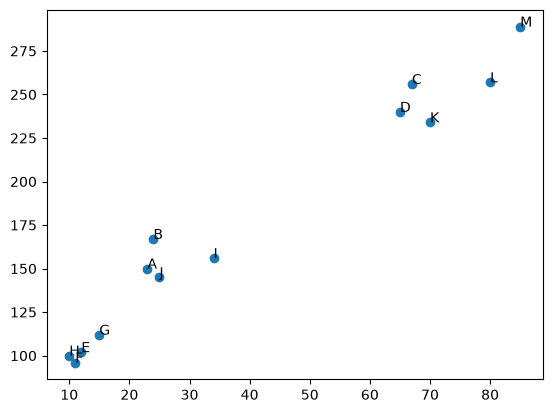

In [2]:
df = pd.read_csv("F:\MACHINE LEARNING\SOMETHING\Datasets\simp_clust.csv", index_col = 0)
plt.scatter(df["X1"] , df["X2"])
for i in range(0, df.shape[0]):
    plt.text(x = df['X1'].values[i],
             y = df['X2'].values[i],
             s = list(df.index)[i])
plt.show()
    

In [3]:
print(df.dtypes)

X1    int64
X2    int64
dtype: object


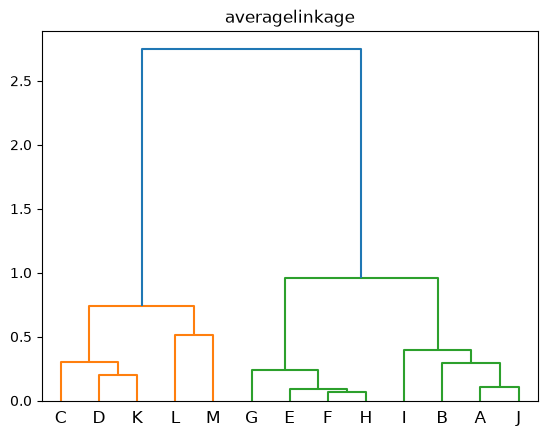

In [4]:
scaler = StandardScaler().set_output(transform = 'pandas')
df_scaled = scaler.fit_transform(df)
link = "average"
mergigns = linkage(df_scaled, method = link)
dendrogram(mergigns, labels = list(df_scaled.index))
plt.title(link + "linkage")
plt.show()

# milk

In [5]:
milk = pd.read_csv("F:\MACHINE LEARNING\SOMETHING\Datasets\milk.csv", index_col = 0)
scaler = StandardScaler().set_output(transform = 'pandas')
scl_milk = scaler.fit_transform(milk)
scl_milk.head()

,water,protein,fat,lactose,ash
Animal,,,,,
HORSE,0.948806,-1.009291,-0.903208,1.542217,-1.037554
ORANGUTAN,0.821407,-1.344603,-0.660619,1.040773,-1.259945
MONKEY,0.813445,-1.121062,-0.738247,1.263637,-1.381249
DONKEY,0.964731,-1.260775,-0.864394,1.152205,-0.936467
HIPPO,0.972694,-1.568145,-0.563583,0.149319,-1.542988


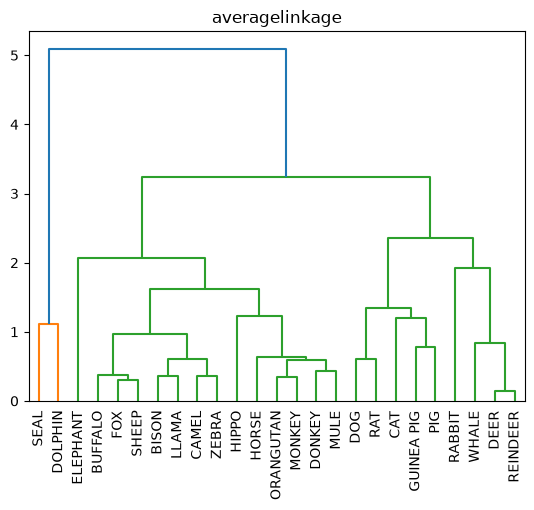

In [6]:
link = "average"
mergigns = linkage(scl_milk, method = link)
dendrogram(mergigns, labels = list(scl_milk.index))
plt.xticks(rotation=90)
plt.title(link + "linkage")
plt.show()

In [7]:
clusters=[2,3,4,5,6,7]
scores=[]
for c in clusters:
    hc=AgglomerativeClustering(n_clusters=c)
    hc.fit(scl_milk)
    scores.append([c,silhouette_score(scl_milk,hc.labels_)])
df_score=pd.DataFrame(scores,columns=['cluster','scores']).sort_values('scores',ascending=False)
df_score


,cluster,scores
1,3,0.539160
0,2,0.525851
2,4,0.443481
3,5,0.398301
5,7,0.380407
4,6,0.375007


In [8]:
pc_milk

NameError: name 'pc_milk' is not defined

In [ ]:
from sklearn.decomposition import PCA
import seaborn as sns

p=PCA().set_output(transform='pandas')
pc_milk=p.fit_transform(scl_milk)
pc_milk['cluster']=hc.labels_
pc_milk['cluster']=pc_milk['cluster'].astype(str)
sns.scatterplot(data=pc_milk,x='pca0',y='pca1',hue='cluster')
for i in range(len(pc_milk)):
    plt.text(pc_milk.pca0.iloc[i],pc_milk.pca1.iloc[i],pc_milk.index[i])




# nutrient

In [ ]:
nutrient=pd.read_csv(r"F:\MACHINE LEARNING\SOMETHING\Datasets\nutrient.csv",index_col=0)
scaler = StandardScaler().set_output(transform = 'pandas')
scl_nut = scaler.fit_transform(nutrient)
scl_nut.head()